In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV
)

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    log_loss
)

from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    StratifiedKFold,
    GridSearchCV
)

In [2]:
from sklearn.datasets import fetch_covtype

data = fetch_covtype()
X = pd.DataFrame(data.data,
                columns = data.feature_names)

y = pd.Series(data.target, name = "Cover_Type")
print(X.shape)
#print(X)
print(y.value_counts)

(581012, 54)
<bound method IndexOpsMixin.value_counts of 0         5
1         5
2         2
3         2
4         5
         ..
581007    3
581008    3
581009    3
581010    3
581011    3
Name: Cover_Type, Length: 581012, dtype: int32>


In [3]:
X_train1,_,y_train1,_ = train_test_split(X,y,train_size =15000,random_state = 42, stratify = y)
X_train,X_test,y_train,y_test = train_test_split(X_train1,
                                                 y_train1,test_size=0.3,
                                                 random_state=42,
                                                 stratify = y_train1)


print("listo")

listo


In [4]:
cv = StratifiedKFold(n_splits=3, shuffle = True, random_state = 42)
param_grid = [
    {
    "svc__kernel": ["rbf"],
    "svc__C": [0.1,1,10,100],
    "svc__gamma": [0.1,1,10]
},
        {
    "svc__kernel": ["linear"],
    "svc__C": [1,10,100]
},
     {"svc__kernel": ["poly"],
    "svc__C": [0.1,1,10],
    "svc__degree": [2,3],
    "svc__gamma": ["scale"]
        }
             ]
modelo = Pipeline(
    [
        ("scaler", StandardScaler()),
        ("svc", SVC())
    ]
)

grid_search = GridSearchCV(
    estimator=modelo,
    param_grid=param_grid,
    scoring="accuracy",
    cv=cv,
    n_jobs=-1,
    return_train_score=True
)


grid_search.fit(X_train, y_train)
print(grid_search.best_params_)
print("Accuracy validacion: ",grid_search.best_score_)
print("Accuracy de prueba: ",accuracy_score(y_test,grid_search.predict(X_test)))

Exception ignored in: <function ResourceTracker.__del__ at 0x7cb0eaf79f80>
Traceback (most recent call last):
  File "/home/gdiek/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/home/gdiek/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/home/gdiek/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x73445c581f80>
Traceback (most recent call last):
  File "/home/gdiek/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/home/gdiek/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/home/gdiek/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ 

{'svc__C': 10, 'svc__gamma': 0.1, 'svc__kernel': 'rbf'}
Accuracy validacion:  0.7826666666666666
Accuracy de prueba:  0.7951111111111111


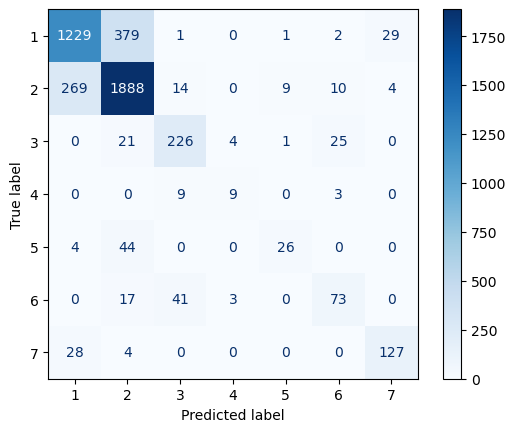

In [7]:

import joblib
#Matriz de confusión
#modelo = grid_search.best_estimator_
#joblib.dump(modelo,"modelo_svm.joblib")


mejor_modelo = joblib.load("modelo_svm.joblib")
ConfusionMatrixDisplay.from_estimator(
    mejor_modelo,
    X_test,
    y_test,
    cmap="Blues"
)

In [9]:
print(classification_report(mejor_modelo.predict(X_test),y_test))

              precision    recall  f1-score   support

           1       0.75      0.80      0.78      1530
           2       0.86      0.80      0.83      2353
           3       0.82      0.78      0.80       291
           4       0.43      0.56      0.49        16
           5       0.35      0.70      0.47        37
           6       0.54      0.65      0.59       113
           7       0.80      0.79      0.80       160

    accuracy                           0.80      4500
   macro avg       0.65      0.73      0.68      4500
weighted avg       0.80      0.80      0.80      4500



### Reporte

Ya que el conjunto de datos tiene demasiando, se seleccionón una muestra aleatoria de 15,00 observaciones. Y luego esta muestra se dividion en conjuntos de entrenamiento y prueba.

Para la selección del modelo se reslizo un Grid seach considerando diferentes kernesl: lineal, radial y polinomial con distintos valores de hiperparametros.

El mejor resultado se obtuvo con un kernel radial con los siguientes hiperparamentros.

C=10 y Gamma=0.1

con este modelo alcanzo un accuracy de 78.27% en validación y de 79.51% en el conjunto de prueba.

despues de eso se obtuvieron los siguientes resultado de clasificación:

              precision    recall  f1-score   support

           1       0.75      0.80      0.78      1530
           2       0.86      0.80      0.83      2353
           3       0.82      0.78      0.80       291
           4       0.43      0.56      0.49        16
           5       0.35      0.70      0.47        37
           6       0.54      0.65      0.59       113
           7       0.80      0.79      0.80       160

    accuracy                           0.80      4500
   macro avg       0.65      0.73      0.68      4500
weighted avg       0.80      0.80      0.80      4500


y el F1 score en macro tiene muchas diferecias lo cual indica que el modelo varia de desempeño dependiendo de las clases. y en particular en clases con mas observacioesn tiene mejor desempeño.

y la matriz de confución permite identificar con que detalle los los errores cometidos por el clasificador. Se puede observar que existe una confusion de observaciones de la clase 1 como clase 2 y viceversa, asi como entre clases 6 y 3. Lo cual puede indicar que muchas cubiertas forestales comparten la misma geografia y por lo cual dificulta su diferenciación.


Por lo que se puede concluir que el modelo se ve bien pero podria mejorarse en el aspecto del balance de las clases.